Dataset shape: (569, 30)
Target classes: ['malignant' 'benign']

Model Evaluation Results:
                     CV Accuracy  Accuracy  Precision  Recall  F1 Score  \
Model                                                                     
Logistic Regression       0.9802    0.9825     0.9861  0.9861    0.9861   
Random Forest             0.9538    0.9561     0.9589  0.9722    0.9655   

                     ROC-AUC  
Model                         
Logistic Regression   0.9954  
Random Forest         0.9937  


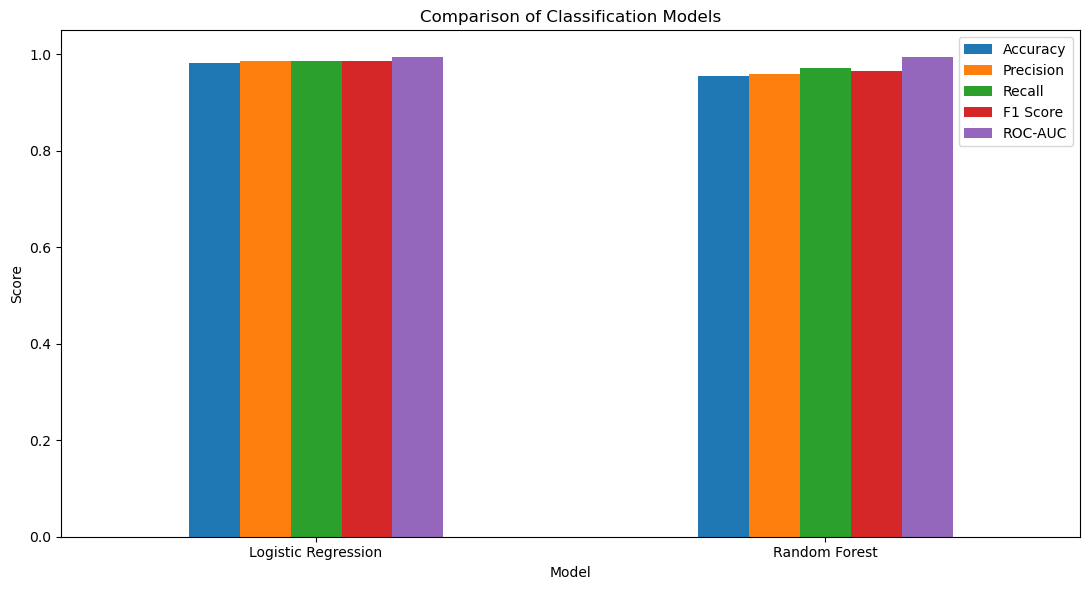


Best Model: Logistic Regression


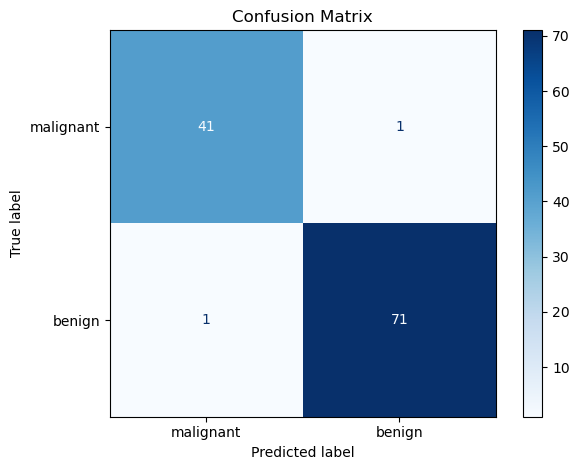

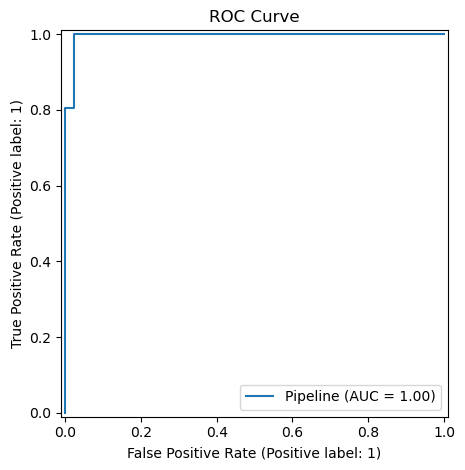

In [2]:


import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay
)

# 1. Load the dataset
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print("Dataset shape:", X.shape)
print("Target classes:", data.target_names)

# 2. Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Create two classification models
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=5000)
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42
    )
}

results = []
trained_models = {}

# 4. Train, cross-validate and evaluate models
for name, model in models.items():
    scores = cross_val_score(
        model, X_train, y_train, cv=5, scoring="accuracy"
    )

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "CV Accuracy": scores.mean(),
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

    trained_models[name] = model

# 5. Display evaluation metrics
results_df = pd.DataFrame(results).set_index("Model")
print("\nModel Evaluation Results:")
print(results_df.round(4))

# 6. Compare model performance using a plot
results_df[["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]].plot(
    kind="bar", figsize=(11, 6), ylim=(0, 1.05)
)
plt.title("Comparison of Classification Models")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 7. Select the model with the highest F1 score
best_name = results_df["F1 Score"].idxmax()
best_model = trained_models[best_name]
best_predictions = best_model.predict(X_test)

print("\nBest Model:", best_name)

# 8. Plot the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, best_predictions,
    display_labels=data.target_names,
    cmap="Blues"
)
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

# 9. Plot the ROC curve
RocCurveDisplay.from_estimator(best_model, X_test, y_test)
plt.title("ROC Curve")
plt.tight_layout()
plt.show()